# Olist: Revenue Forecast and Freight Regression

Two questions on the Olist Brazilian E-Commerce data (Kaggle), using delivered orders only:

1. **Forecasting:** how well can next month's revenue be predicted, and which simple method works best?
2. **Regression:** what drives freight cost per item, and how well can it be predicted on unseen orders?

**Data:** a flat file with one row per order item, `cleaned_combined_view.csv` (the joined orders, items, products and customers tables). Put it in the same folder as this notebook.

A companion notebook, `olist_statistical_analysis.ipynb`, tests the same relationships formally (hypothesis tests, intervals, diagnostics). It fits the regression on all rows, so its coefficients differ slightly from the training-set figures here. The link between weight and freight was first found in the capstone's Part 2 (r = 0.61); this notebook uses it to forecast and predict.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

DATA_PATH = "cleaned_combined_view.csv"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 0. Load and filter the data

In [2]:
df = pd.read_csv(DATA_PATH)
d = df[df.order_status == "delivered"].copy()
d["ts"] = pd.to_datetime(d.order_purchase_timestamp)
print(f"Delivered item rows: {len(d):,} | delivered orders: {d.order_id.nunique():,}")

Delivered item rows: 110,197 | delivered orders: 96,478


## 1. Forecasting monthly revenue

**Approach.** Revenue is a time series, so a random train/test split would leak the future into the past. Instead I use a **rolling-origin backtest**: for each month from January 2018, fit on all earlier months, forecast the next month, then compare with what happened.

**Months used:** January 2017 to August 2018. 2016 has almost no orders, and September 2018 is a partial month, so both are left out.

20 months: 2017-01 to 2018-08


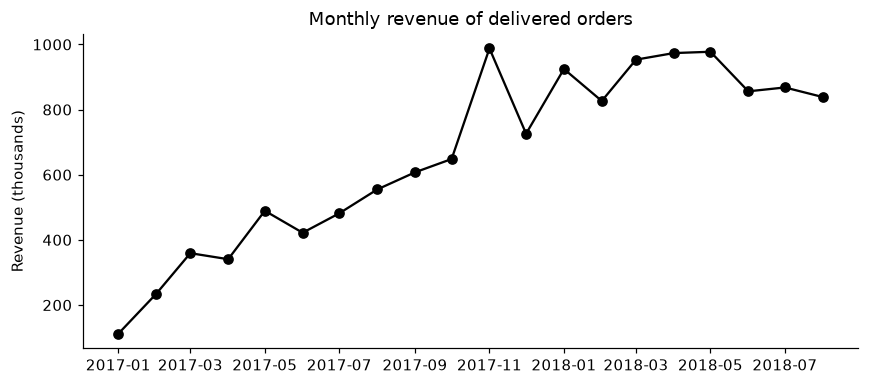

In [3]:
m = d.groupby(d.ts.dt.to_period("M")).price.sum()
m = m["2017-01":"2018-08"]
y = m.values
print(f"{len(y)} months: {m.index[0]} to {m.index[-1]}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(m.index.to_timestamp(), y / 1e3, marker="o", color="black")
ax.set_ylabel("Revenue (thousands)")
ax.set_title("Monthly revenue of delivered orders")
plt.tight_layout(); plt.show()

Revenue grew quickly through 2017, spiked in November 2017, and then flattened in 2018. A method that assumes steady growth will therefore overshoot in 2018.

**Four methods, from simplest to most structured:**

- **Naive:** next month equals last month.
- **3-month moving average:** the mean of the last three months.
- **Linear trend:** a straight line fitted to all earlier months.
- **Seasonal naive:** the same month last year.

In [4]:
def f_naive(h):    return h[-1]
def f_ma3(h):      return h[-3:].mean()
def f_trend(h):
    x = np.arange(len(h)).reshape(-1, 1)
    return LinearRegression().fit(x, h).predict([[len(h)]])[0]
def f_seasonal(h): return h[-12]

methods = {"Naive (last month)": f_naive, "3-month moving average": f_ma3,
           "Linear trend": f_trend, "Seasonal naive (same month last year)": f_seasonal}

start = 12   # first forecast is January 2018, using 12 months of history
rows, preds = [], {}
for name, fn in methods.items():
    p = np.array([fn(y[:t]) for t in range(start, len(y))])
    a = y[start:]
    preds[name] = p
    rows.append((name, mean_absolute_error(a, p), 100 * np.mean(np.abs((a - p) / a))))

res = pd.DataFrame(rows, columns=["method", "MAE", "MAPE_%"]).sort_values("MAPE_%").reset_index(drop=True)
res.round(1)

,method,MAE,MAPE_%
0,Naive (last month),76330.8,8.5
1,3-month moving average,86449.5,9.6
2,Linear trend,138188.8,15.9
3,Seasonal naive (same month last year),528083.6,58.2


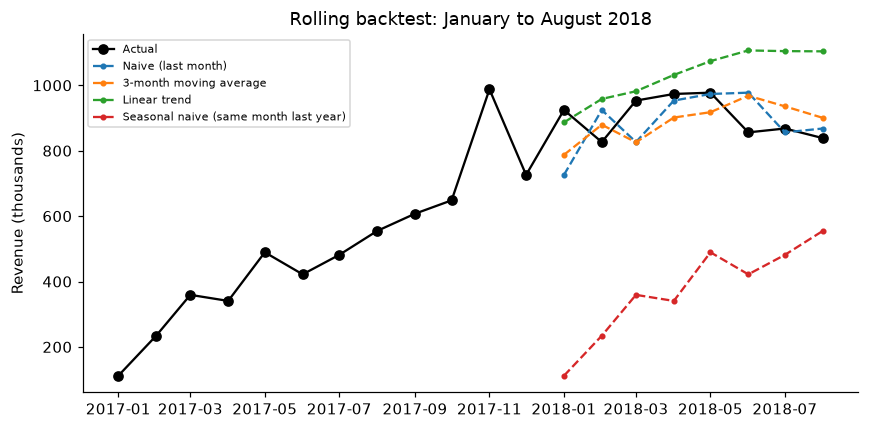

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(m.index.to_timestamp(), y / 1e3, marker="o", color="black", label="Actual")
for name, p in preds.items():
    ax.plot(m.index[start:].to_timestamp(), p / 1e3, marker=".", linestyle="--", label=name)
ax.set_ylabel("Revenue (thousands)")
ax.set_title("Rolling backtest: January to August 2018")
ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Reading the result.**

- The **naive** forecast is best, with a mean absolute percentage error (MAPE) of about **8.5%**. The 3-month average is close behind at about 9.6%.
- The **linear trend** is worse (about 15.9%) because growth slowed in 2018, so the line keeps climbing while revenue does not.
- **Seasonal naive** is far off (about 58%) because 2017 revenue was much lower than 2018 revenue, so last year's figure is the wrong scale.

**Limits.** Twenty months is too short to learn yearly seasonality, so the November 2017 spike cannot be predicted from earlier data. With only eight forecasts, the ranking of methods is indicative.

## 2. Regression: what drives freight per item?

**Approach.** Predict `freight_value` for each order item from its **weight**, its **price**, and the customer's **state**. The data is split 80/20 at random, the model is fitted on the 80%, and every score below is measured on the unseen 20%.

A **mean-only baseline** (always predict the average training freight) shows how much the model adds. São Paulo (SP) is the reference state, so each state's coefficient is its premium over SP.

In [6]:
r = d.dropna(subset=["product_weight_g", "price", "freight_value", "customer_state"]).copy()
r["weight_kg"] = r.product_weight_g / 1000

X = pd.get_dummies(r[["weight_kg", "price", "customer_state"]], columns=["customer_state"], dtype=float)
X = X.drop(columns=["customer_state_SP"])   # SP is the reference state
target = r.freight_value

Xtr, Xte, ytr, yte = train_test_split(X, target, test_size=0.2, random_state=42)
print(f"Train rows {len(Xtr):,} | test rows {len(Xte):,} | features {X.shape[1]}")

Train rows 88,157 | test rows 22,040 | features 28


In [7]:
lin = LinearRegression().fit(Xtr, ytr)
pred = lin.predict(Xte)
base = np.full(len(yte), ytr.mean())
rmse = lambda a, b: np.sqrt(mean_squared_error(a, b))

scores = pd.DataFrame({
    "R-squared": [r2_score(yte, pred), 0.0],
    "RMSE": [rmse(yte, pred), rmse(yte, base)],
    "MAE": [mean_absolute_error(yte, pred), mean_absolute_error(yte, base)],
}, index=["Linear regression", "Mean-only baseline"])
scores.round(3)

,R-squared,RMSE,MAE
Linear regression,0.543,10.237,5.403
Mean-only baseline,0.000,15.150,8.520


In [8]:
coef = pd.Series(lin.coef_, index=X.columns)
print(f"Each extra kg of weight adds {coef['weight_kg']:.2f} to freight, holding price and state fixed.")
print(f"Each extra 100 of price adds {100 * coef['price']:.2f} to freight, holding weight and state fixed.")
print()
print("Largest state premiums over SP, holding weight and price fixed:")
(coef.filter(like="customer_state_").sort_values(ascending=False)
     .head(5).rename(lambda s: s.replace("customer_state_", "")).round(2))

Each extra kg of weight adds 2.27 to freight, holding price and state fixed.
Each extra 100 of price adds 1.74 to freight, holding weight and state fixed.

Largest state premiums over SP, holding weight and price fixed:


RR    28.81
PB    25.61
RO    24.77
PI    23.14
MA    22.97
dtype: float64

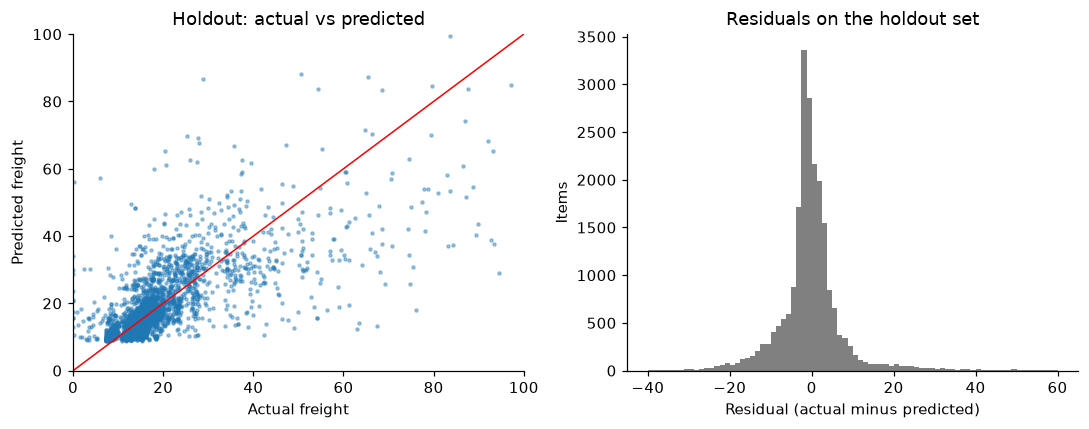

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

idx = np.random.RandomState(0).choice(len(yte), 3000, replace=False)
axes[0].scatter(np.asarray(yte)[idx], pred[idx], s=4, alpha=0.4)
axes[0].plot([0, 100], [0, 100], color="red", linewidth=1)
axes[0].set(xlim=(0, 100), ylim=(0, 100), xlabel="Actual freight", ylabel="Predicted freight",
            title="Holdout: actual vs predicted")

resid = np.asarray(yte) - pred
axes[1].hist(resid, bins=80, range=(-40, 60), color="gray")
axes[1].set(xlabel="Residual (actual minus predicted)", ylabel="Items", title="Residuals on the holdout set")
plt.tight_layout(); plt.show()

**Reading the result.**

- The model explains about **54% of the variation** in freight on unseen items (test R-squared 0.543). Its error (RMSE about 10.2) is clearly lower than the baseline's (about 15.2).
- **Weight** matters: each extra kilogram adds about 2.3 to freight. **Price** adds a little, about 1.7 per extra 100.
- **Location** matters most for remote states. Customers in **RR, PB and RO** pay about 25 to 29 more than comparable customers in SP.
- The residual plot is skewed to the right: some items cost much more to ship than the model predicts.

**Limits.** Distance, carrier and package dimensions are not in the data, so about 46% of the variation is unexplained.

### Does a more flexible model do better?

A linear model assumes each factor adds a fixed amount. Gradient boosting can capture interactions, for example weight mattering more in remote states. It is fitted on the same training rows and scored on the same holdout rows.

In [10]:
hgb = HistGradientBoostingRegressor(random_state=42).fit(Xtr, ytr)
pred_h = hgb.predict(Xte)

compare = pd.DataFrame({
    "R-squared": [r2_score(yte, pred), r2_score(yte, pred_h)],
    "RMSE": [rmse(yte, pred), rmse(yte, pred_h)],
    "MAE": [mean_absolute_error(yte, pred), mean_absolute_error(yte, pred_h)],
}, index=["Linear regression", "Gradient boosting"])
compare.round(3)

,R-squared,RMSE,MAE
Linear regression,0.543,10.237,5.403
Gradient boosting,0.587,9.738,5.082


Gradient boosting raises the holdout R-squared from **0.543 to 0.590** and lowers the RMSE from about 10.2 to about 9.7. The gain is real but modest: weight, price and state already capture most of the signal. The linear model is still the better one for **explaining** freight, because its coefficients can be read directly.

## Summary

| Question | Method | Result |
|---|---|---|
| Next-month revenue | Rolling backtest, January to August 2018 | Naive forecast best (MAPE about 8.5%); the trend and seasonal methods do worse. |
| Drivers of freight | Linear regression, 80/20 holdout | Test R-squared 0.543, RMSE about 10.2 against about 15.2 for a mean-only baseline. Weight and remote states raise freight most. |
| Flexible model | Gradient boosting, same split | Test R-squared 0.590 and RMSE about 9.7: a modest gain over the linear model. |

**To rerun:** place `cleaned_combined_view.csv` beside this notebook and run all cells. Needs pandas, numpy, scikit-learn and matplotlib.